In [74]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
df = pd.read_csv('data/listings.csv.gz')
len(df)

4961

In [3]:
df.columns

Index(['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name',
       'description', 'neighborhood_overview', 'picture_url', 'host_id',
       'host_url', 'host_profile_id', 'host_profile_url', 'host_name',
       'host_since', 'hosts_time_as_user_years', 'hosts_time_as_user_months',
       'hosts_time_as_host_years', 'hosts_time_as_host_months',
       'host_location', 'host_about', 'host_response_time',
       'host_response_rate', 'host_acceptance_rate', 'host_is_superhost',
       'host_thumbnail_url', 'host_picture_url', 'host_neighbourhood',
       'host_listings_count', 'host_total_listings_count',
       'host_verifications', 'host_has_profile_pic', 'host_identity_verified',
       'neighbourhood', 'neighbourhood_cleansed',
       'neighbourhood_group_cleansed', 'latitude', 'longitude',
       'property_type', 'room_type', 'accommodates', 'bathrooms',
       'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price',
       'price_quote_checkin_date', 'price_quote_c

In [4]:
df.head().T

,0,1,2,3,4
id,1434108413206019816,1613802572207908117,1674132228660847237,43057420,43057598
listing_url,https://www.airbnb.com/rooms/1434108413206019816,https://www.airbnb.com/rooms/1613802572207908117,https://www.airbnb.com/rooms/1674132228660847237,https://www.airbnb.com/rooms/43057420,https://www.airbnb.com/rooms/43057598
scrape_id,20260922161643,20260922161643,20260922161643,20260922161643,20260922161643
last_scraped,2026-09-24,2026-09-24,2026-09-24,2026-09-24,2026-09-24
source,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...
calculated_host_listings_count,1,212,1,13,13
calculated_host_listings_count_entire_homes,1,211,1,13,13
calculated_host_listings_count_private_rooms,0,1,0,0,0
calculated_host_listings_count_shared_rooms,0,0,0,0,0


Check the missing values

In [5]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

neighborhood_overview           4961
host_since                      4961
host_acceptance_rate            4961
host_response_rate              4961
host_response_time              4961
host_total_listings_count       4961
host_neighbourhood              4961
host_verifications              4961
host_thumbnail_url              4961
calendar_updated                4961
bathrooms                       4961
neighbourhood_group_cleansed    4961
neighbourhood                   4961
instant_bookable                4961
source                          4526
host_about                      2750
host_location                   1855
first_review                     571
reviews_per_month                571
review_scores_checkin            571
review_scores_accuracy           571
review_scores_rating             571
review_scores_cleanliness        571
review_scores_communication      571
review_scores_location           571
review_scores_value              571
last_review                      571
e

Delete data with empty or almost empty columns  

In [6]:
columns_empty = missing[missing > len(df)*0.9].index
df = df.drop(columns=columns_empty)
len(df)

4961

In [7]:
columns_empty

Index(['source', 'neighborhood_overview', 'host_since', 'host_response_time',
       'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url',
       'host_neighbourhood', 'host_total_listings_count', 'host_verifications',
       'neighbourhood', 'neighbourhood_group_cleansed', 'bathrooms',
       'calendar_updated', 'instant_bookable'],
      dtype='str')

Delete data with missing price

In [8]:
df = df.drop(df[df.price.isnull()].index)
len(df)

4627

In [9]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

host_about                     2544
host_location                  1717
review_scores_communication     501
review_scores_location          501
first_review                    501
review_scores_rating            501
last_review                     501
reviews_per_month               501
review_scores_value             501
review_scores_cleanliness       501
review_scores_accuracy          501
review_scores_checkin           501
license                          93
beds                             47
has_availability                  6
minimum_minimum_nights            3
maximum_minimum_nights            3
minimum_nights                    3
maximum_nights                    3
minimum_maximum_nights            3
maximum_maximum_nights            3
bathrooms_text                    1
description                       1
dtype: int64

Delete some unfinished offers. First to check if it the same raws

In [10]:
cols = missing[missing == 3].index
df[cols].isnull().any(axis=1).sum()

np.int64(3)

In [11]:
df = df.dropna(subset=cols)
len(df)

4624

Dropping the raw with bathrom description missing

In [12]:
df = df.drop(df[df.bathrooms_text.isnull()].index)
len(df)

4623

Analyse whats left

In [13]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

host_about                     2541
host_location                  1716
last_review                     501
first_review                    501
review_scores_rating            501
review_scores_checkin           501
review_scores_cleanliness       501
review_scores_accuracy          501
review_scores_location          501
review_scores_value             501
reviews_per_month               501
review_scores_communication     501
license                          92
beds                             47
has_availability                  6
description                       1
dtype: int64

In [14]:
df['host_location'].value_counts()

host_location
Thessaloniki, Greece      2410
Greece                      96
Athens, Greece              56
Heraklion, Greece           39
London, United Kingdom      24
                          ... 
Israel                       1
Paris, France                1
Strasbourg, France           1
Cologne, Germany             1
Nicosia, Cyprus              1
Name: count, Length: 121, dtype: int64

Feature engineering

1. Host location (categories)

In [15]:
def host_location_category(loc): 
    if pd.isna(loc): 
        return 'unknown' 
    if 'Thessaloniki' in loc: 
        return 'thessaloniki' 
    if'Greece' in loc: 
        return 'greece'
    return 'abroad' 
    
df['host_location_cat'] = df['host_location'].apply(host_location_category) 

In [16]:
df['host_location_cat'].value_counts()

host_location_cat
thessaloniki    2410
unknown         1716
greece           372
abroad           125
Name: count, dtype: int64

2. Reviews
   a) make a new column 'has_reviews'
   b) 'reviews_per_month    ' fill with 0

In [17]:
def has_reviews_category(loc): 
    if loc == 0: 
        return 0 
    return 1 
    
df['has_reviews'] = df['number_of_reviews'].apply(has_reviews_category) 

In [18]:
df['has_reviews'].value_counts()

has_reviews
1    4122
0     501
Name: count, dtype: int64

In [19]:
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

In [20]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

host_about                     2541
host_location                  1716
last_review                     501
first_review                    501
review_scores_cleanliness       501
review_scores_accuracy          501
review_scores_rating            501
review_scores_communication     501
review_scores_location          501
review_scores_value             501
review_scores_checkin           501
license                          92
beds                             47
has_availability                  6
description                       1
dtype: int64

3. License

In [21]:
df['license'].value_counts()

license
Exempt              36
0933Κ13000111100    15
0933Κ13000118900    15
0933Κ13000125400    11
1037314             10
                    ..
00003955113          1
36234670000          1
0933Κ13000130600     1
00003652492          1
00003941335          1
Name: count, Length: 4244, dtype: int64

In [22]:
def license_ok(loc): 
    if pd.isna(loc): 
        return 0
    return 1 
    
df['license_ok'] = df['license'].apply(license_ok) 

In [23]:
df['license_ok'].value_counts()

license_ok
1    4531
0      92
Name: count, dtype: int64

In [24]:
df['has_availability'].value_counts()

has_availability
t    4617
Name: count, dtype: int64

Delete non unique columns

In [25]:
df.nunique().sort_values(ascending=True)

scrape_id                    1
has_availability             1
host_has_profile_pic         2
last_scraped                 2
host_identity_verified       2
                          ... 
license                   4244
name                      4552
picture_url               4574
id                        4623
listing_url               4623
Length: 78, dtype: int64

In [26]:
nunique = df.nunique()
columns_nonunique = nunique[nunique == 1].index
df = df.drop(columns=columns_nonunique)


Cleaning price

In [27]:
df['price'].head()

0    $96.60
1    $40.00
2    $60.00
3    $94.00
4    $94.00
Name: price, dtype: str

In [28]:
df['price'] = df['price'].str.replace('$', '')
df['price'] = df['price'].str.replace(',', '')

df.price = pd.to_numeric(df.price)
df.price.head()

0    96.6
1    40.0
2    60.0
3    94.0
4    94.0
Name: price, dtype: float64

Cleaning dates (new columns - to count how many days from the first review and from the last, the days will be counted from the last scraped date)

In [29]:
df.columns

Index(['id', 'listing_url', 'last_scraped', 'name', 'description',
       'picture_url', 'host_id', 'host_url', 'host_profile_id',
       'host_profile_url', 'host_name', 'hosts_time_as_user_years',
       'hosts_time_as_user_months', 'hosts_time_as_host_years',
       'hosts_time_as_host_months', 'host_location', 'host_about',
       'host_is_superhost', 'host_picture_url', 'host_listings_count',
       'host_has_profile_pic', 'host_identity_verified',
       'neighbourhood_cleansed', 'latitude', 'longitude', 'property_type',
       'room_type', 'accommodates', 'bathrooms_text', 'bedrooms', 'beds',
       'amenities', 'price', 'price_quote_checkin_date',
       'price_quote_checkout_date', 'price_quote_total_price',
       'price_quote_price_per_night', 'price_quote_raw', 'minimum_nights',
       'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights',
       'minimum_maximum_nights', 'maximum_maximum_nights',
       'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'av

In [36]:
df['days_since_last_review'] = (pd.to_datetime(df.last_scraped) - pd.to_datetime(df.last_review)).dt.days
df['days_since_last_review'].isnull().sum()

np.int64(501)

In [37]:
df['days_since_first_review'] = (pd.to_datetime(df.last_scraped) - pd.to_datetime(df.first_review)).dt.days
df['days_since_first_review'].isnull().sum()

np.int64(501)

EDA

In [ ]:
Analyse price

In [45]:
df['price'].describe()

count     4623.000000
mean       100.878890
std        259.006708
min         18.290000
25%         63.000000
50%         80.000000
75%        108.000000
max      12021.500000
Name: price, dtype: float64

<Axes: xlabel='price', ylabel='Count'>

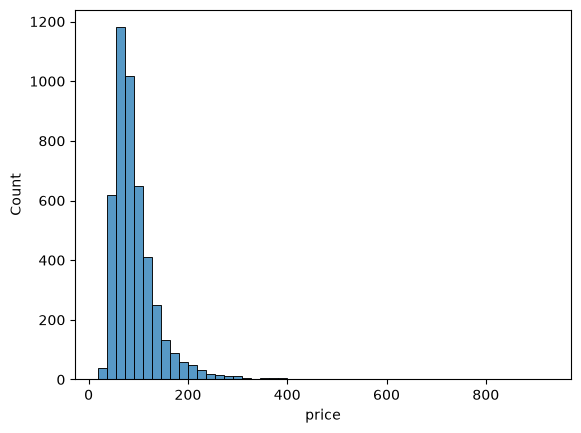

In [48]:
sns.histplot(df.price[df.price < 1000], bins=50)

In [52]:
df.price[df.price > 1000]

135      1651.00
790     12021.50
1477     5776.50
2979     2316.27
4242    10700.50
4294     1157.00
Name: price, dtype: float64

Delete prices > 1000

In [59]:
df = df.drop(df[df.price > 1000].index)
len(df)


4617

In [61]:
df['price'].skew()

np.float64(4.696697731902987)

Check if it looks like real adv (from 500 and up)

In [71]:
pd.set_option('display.max_colwidth', 200)
df[df.price > 500].description

233                       Next to the Rotunda, Rock n' Roll 1 is a unique apartment. With unique aesthetics and decoration, fully equipped, in the city center, next to all the great monuments of Thessaloniki
234         Rock n Roll 2 is a unique apartment next to the Rotunda.  In a very central location, a fully equipped house with unique aesthetics and decoration. Next to all the great monuments of Thessaloniki
1036                                                                                                                                          The apartment has modern decoration, has a fully equipped kitchen
1078    The apartment has 1 large bedroom with a double bed, a living room with two sofas where one becomes a comfortable bed, a fully equipped kitchen, a bathroom,  and a small room with a single bed. Th...
1112    This flat 130 sq.m. is located in the most desirable place of Thessaloniki between Aristotelous square and White Tower. <br />It consists of a large living area

Apply log

In [75]:
df['log_price'] = np.log1p(df['price'])
df['log_price'].skew()

np.float64(0.7727375662648258)

<Axes: xlabel='log_price', ylabel='Count'>

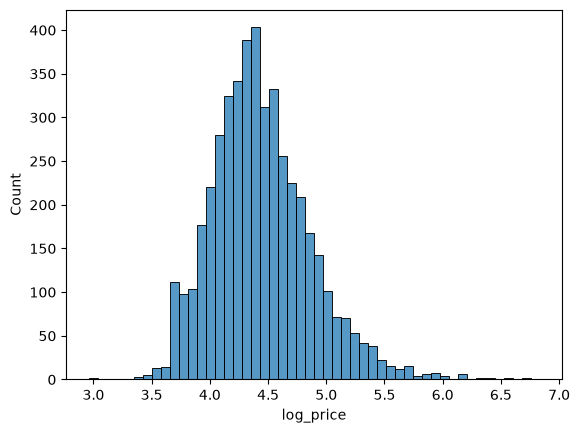

In [76]:
sns.histplot(df.log_price, bins=50)

Skew of Price: 4.69
Skew of Log Price: 0.77
After the log transformation, skewness dropped from 4.69 to 0.77(moderate), so the model will be trained on log_price